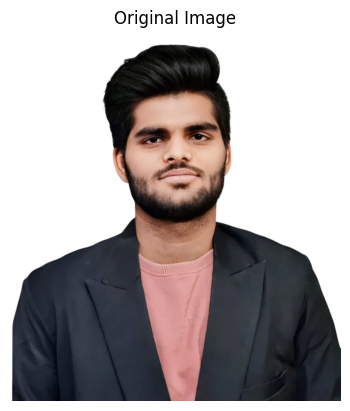

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('profile.jpg')
if image is None:
    raise FileNotFoundError('Keep profile.jpg in the notebook folder.')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.title('Original Image')
plt.axis('off')
plt.show()

In [2]:
kernels = {
    'Identity': np.array([[0,0,0],[0,1,0],[0,0,0]], dtype=np.float32),
    'Box Blur': np.ones((9,9), dtype=np.float32) / 81,
    'Gaussian Blur': cv2.getGaussianKernel(15, 3) @ cv2.getGaussianKernel(15, 3).T,
    'Sharpening': np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=np.float32),
    'Edge Detection': np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]], dtype=np.float32),
    'Emboss': np.array([[-2,-1,0],[-1,1,1],[0,1,2]], dtype=np.float32),
    'Motion Blur': np.zeros((21,21), dtype=np.float32)
}
kernels['Motion Blur'][10, :] = 1 / 21

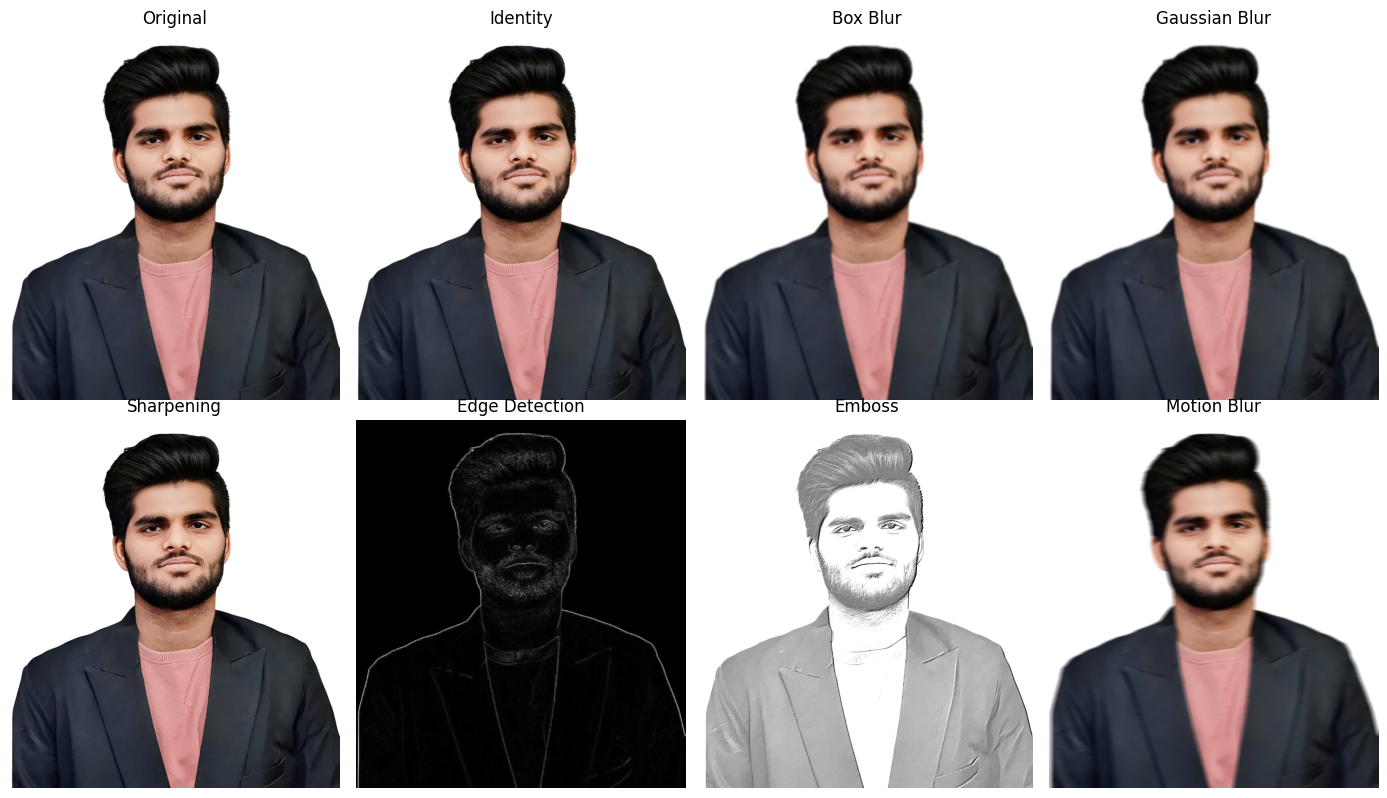

In [3]:
results = {}
for name, kernel in kernels.items():
    flipped = cv2.flip(kernel, -1)
    if name == 'Edge Detection':
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        filtered = cv2.filter2D(gray, cv2.CV_32F, flipped)
        results[name] = np.clip(np.abs(filtered), 0, 255).astype(np.uint8)
    elif name == 'Emboss':
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        results[name] = cv2.filter2D(gray, -1, flipped, delta=128)
    else:
        results[name] = cv2.filter2D(image, -1, flipped)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, (name, output) in zip(axes.flat, [('Original', image)] + list(results.items())):
    ax.imshow(output, cmap='gray' if output.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

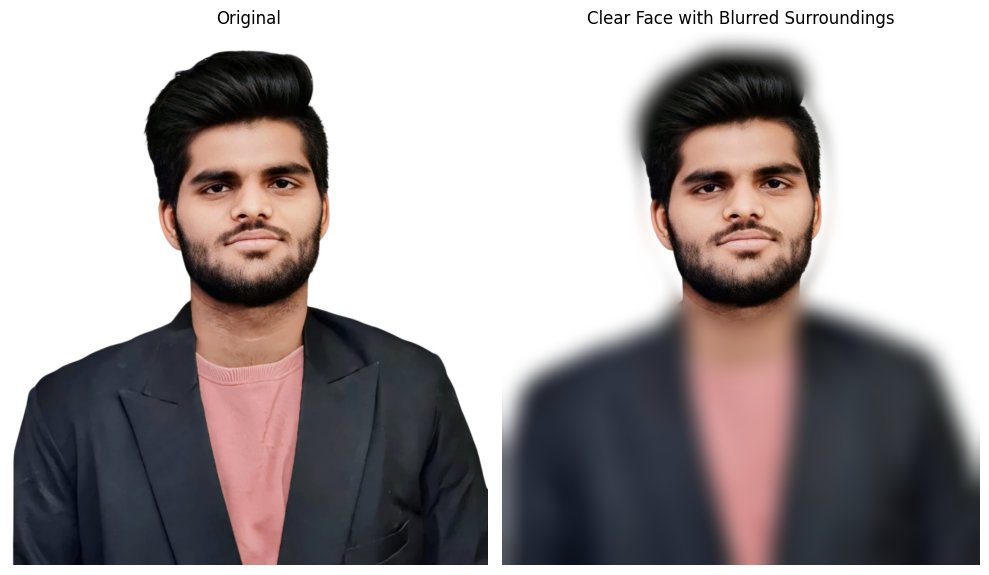

In [4]:
blurred = cv2.GaussianBlur(image, (101, 101), 25)
height, width = image.shape[:2]
mask = np.zeros((height, width), dtype=np.float32)
center = (int(width * 0.49), int(height * 0.30))
axes = (int(width * 0.20), int(height * 0.24))
cv2.ellipse(mask, center, axes, 0, 0, 360, 1, -1)
mask = cv2.GaussianBlur(mask, (61, 61), 12)
mask = mask[:, :, None]
output = (image * mask + blurred * (1 - mask)).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, photo, title in zip(axes, [image, output], ['Original', 'Clear Face with Blurred Surroundings']):
    ax.imshow(photo)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()